

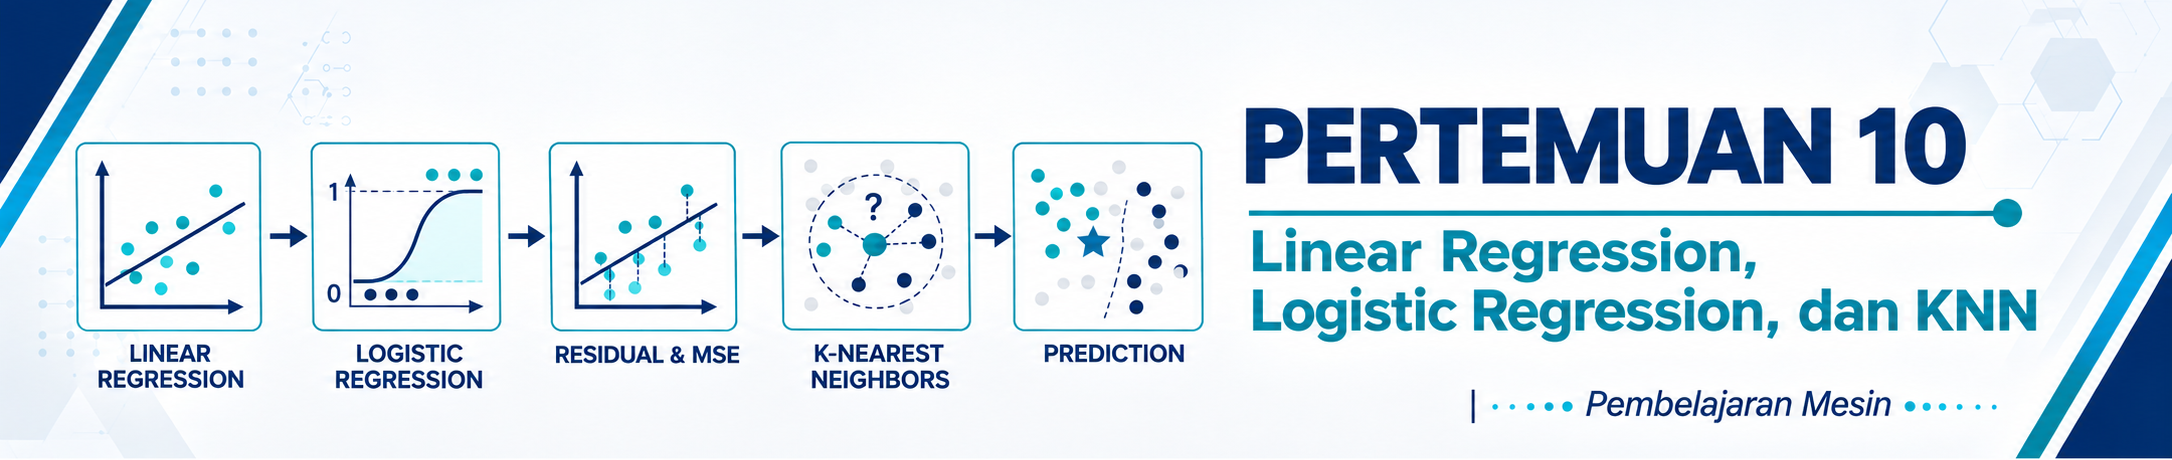

**Mata kuliah:** DAIS32W — Pembelajaran Mesin · **Nama:** Bartolomeus Simanjuntak · **NIM:** 255314091 · **Kelas:** Pembelajaran Mesin EP

### Praktikum data nyata: EDA → modeling → ablation → evaluasi

**Dataset:** `load_diabetes(scaled=False)` (442 observasi, 10 fitur, target numerik) dan `load_iris()` (150 bunga, empat fitur, tiga spesies), keduanya dari scikit-learn. Contoh manual memakai baris Iris asli; koefisien Logistic Regression pada bagian ilustrasi adalah angka asumsi untuk menjelaskan sigmoid, bukan hasil fit data.

**Alur:** perhitungan LR → EDA/split Diabetes → Linear Regression vs KNNRegressor → dua contoh KNNClassifier → EDA/split Iris → ablation KNN → Logistic Regression sebagai pembanding pada Iris → kunci final → test sekali → laporan. **Dilarang menggunakan TEST untuk tuning.**

## P0 — Persiapan lingkungan dan sumber data
**JALANKAN CELL BERIKUT.** Semua data dibaca langsung dari library; tidak perlu `locate_data()` atau `Path()`. Jika ingin menggunakan berkas CSV pendamping, hasilnya harus identik. Paket: NumPy, pandas, matplotlib, scikit-learn.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.datasets import load_diabetes, load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             f1_score, accuracy_score, balanced_accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay)
SEED=2026
pd.set_option('display.max_columns', 15)
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__)
print('Random seed:', SEED)

Python: 3.14.7 | scikit-learn: 1.9.1
Random seed: 2026


## P1 — Verifikasi perhitungan manual Linear Regression

Materi teori memakai **4 observasi** untuk latihan mekanisme: `x = [0, 1, 2, 3]`, `y = [1, 3, 5, 7]`. Persamaan model adalah **prediksi = w × x + b**. Tujuan pelatihan: memperkecil MSE (*Mean Squared Error*).

### Rumus 1. Prediksi dan kesalahan

$$
\hat{y}_i = w x_i + b
$$

$$
e_i=\hat{y}_i-y_i
$$

### Rumus 2. MSE (*rata-rata kesalahan kuadrat*)

$$
\mathrm{MSE}=\frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i)^2
$$

### Rumus 3. *Batch gradient* — menghitung arah perubahan w dan b

$$
\boxed{\frac{\partial\,\mathrm{MSE}}{\partial w}=\frac{2}{n}\sum_{i=1}^{n} x_i\left(\hat{y}_i-y_i\right)}
$$

$$
\boxed{\frac{\partial\,\mathrm{MSE}}{\partial b}=\frac{2}{n}\sum_{i=1}^{n}\left(\hat{y}_i-y_i\right)}
$$

**Cara membaca:** gradien terhadap `w` adalah dua dibagi jumlah observasi, dikalikan jumlah dari `x_i × (prediksi_i − nilai_sebenarnya_i)` untuk seluruh observasi. Gradien terhadap `b` menggunakan rata-rata kesalahan tanpa perkalian `x_i`.

**Makna *batch*:** semua **4 observasi** dipakai untuk menghitung gradien **sebelum satu kali pembaruan** koefisien. Jadi, satu iterasi bukan berarti memproses satu titik saja.

### Rumus 4. Pembaruan parameter (*gradient descent*)

$$
w_{\mathrm{baru}}=w_{\mathrm{lama}}-\alpha\,\frac{\partial\,\mathrm{MSE}}{\partial w}
$$

$$
b_{\mathrm{baru}}=b_{\mathrm{lama}}-\alpha\,\frac{\partial\,\mathrm{MSE}}{\partial b}
$$

Keterangan: `n` = jumlah observasi (di sini 4); `x_i` = fitur titik ke-i; `y_i` = nilai sebenarnya; `ŷ_i` = prediksi; `w` = koefisien; `b` = intercept; `α` = *learning rate* (langkah pembaruan). Pada contoh ini **w = 0, b = 0, α = 0,1** saat mulai.

**Bentuk teks cadangan** (jika perangkat belum merender persamaan matematika):

```text
grad_w = (2/n) * SUM[ x_i * (prediksi_i - y_i) ]
grad_b = (2/n) * SUM[ prediksi_i - y_i ]
w_baru = w_lama - alpha * grad_w
b_baru = b_lama - alpha * grad_b
```

**Tugas:** hitung iterasi pertama dan kedua dahulu pada lembar kerja teori. Setelah itu, jalankan sel kode berikut untuk memeriksa nilai `grad_w`, `grad_b`, koefisien, prediksi, dan MSE.

,iterasi,w_sebelum,b_sebelum,pred_x3,MSE,grad_w,grad_b
0,0,0.00000,0.00000,0.00000,21.00000,-17.00000,-8.00000
1,1,1.70000,0.80000,5.90000,0.53500,-2.70000,-1.30000
2,2,1.97000,0.93000,6.84000,0.01435,-0.42000,-0.23000
3,3,2.01200,0.95300,6.98900,0.00102,-0.05700,-0.05800
4,4,2.01770,0.95880,7.01190,0.00061,0.00030,-0.02930
5,5,2.01767,0.96173,7.01474,0.00053,0.00888,-0.02353
6,6,2.01678,0.96408,7.01443,0.00047,0.00972,-0.02149
7,7,2.01581,0.96623,7.01366,0.00041,0.00936,-0.02011
8,8,2.01487,0.96824,7.01286,0.00037,0.00884,-0.01889
9,9,2.01399,0.97013,7.01210,0.00032,0.00832,-0.01777


Perkiraan y pada x=4 setelah update akhir: 9.0217


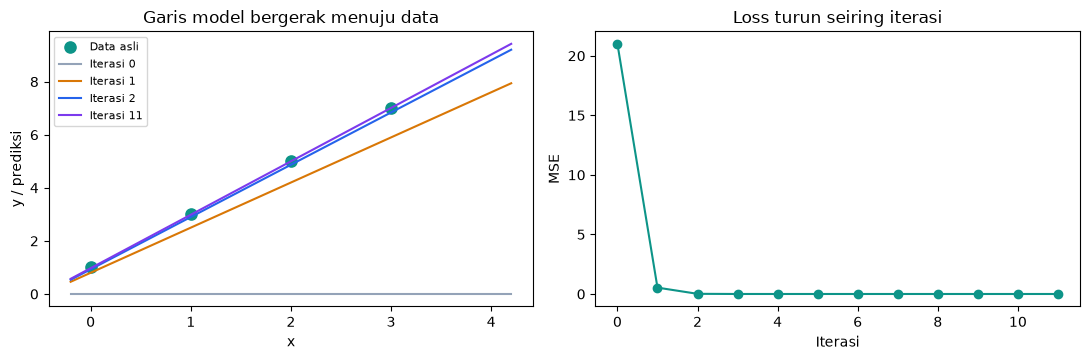

In [2]:
x_manual=np.array([0.,1.,2.,3.]); y_manual=np.array([1.,3.,5.,7.]); alpha=0.10
w,b=0.,0.; rows=[]; predictions={}
for t in range(12):
    y_hat=w*x_manual+b
    error=y_hat-y_manual
    grad_w=2*np.mean(x_manual*error)
    grad_b=2*np.mean(error)
    rows.append({'iterasi':t,'w_sebelum':w,'b_sebelum':b,'pred_x3':y_hat[-1],
                 'MSE':np.mean(error**2),'grad_w':grad_w,'grad_b':grad_b})
    if t in [0,1,2,3,11]: predictions[t]=y_hat.copy()
    w=w-alpha*grad_w
    b=b-alpha*grad_b
gd_table=pd.DataFrame(rows)
display(gd_table.round(5))
assert np.isclose(gd_table.loc[0,'grad_w'],-17.0)
assert np.isclose(gd_table.loc[0,'grad_b'],-8.0)
assert np.isclose(gd_table.loc[1,'w_sebelum'],1.7)
assert np.isclose(gd_table.loc[1,'b_sebelum'],0.8)
assert np.isclose(gd_table.loc[2,'w_sebelum'],1.97)
assert np.isclose(gd_table.loc[2,'b_sebelum'],0.93)
print('Perkiraan y pada x=4 setelah update akhir:',round(w*4+b,4))
fig,axs=plt.subplots(1,2,figsize=(11,3.7))
axs[0].scatter(x_manual,y_manual,color='#0d9488',s=65,label='Data asli')
xx=np.linspace(-.2,4.2,100)
for t,c in [(0,'#94a3b8'),(1,'#d97706'),(2,'#2563eb'),(11,'#7c3aed')]:
    axs[0].plot(xx,gd_table.loc[t,'w_sebelum']*xx+gd_table.loc[t,'b_sebelum'],label=f'Iterasi {t}',color=c)
axs[0].set(xlabel='x',ylabel='y / prediksi',title='Garis model bergerak menuju data');axs[0].legend(fontsize=8)
axs[1].plot(gd_table['iterasi'],gd_table['MSE'],marker='o',color='#0d9488')
axs[1].set(xlabel='Iterasi',ylabel='MSE',title='Loss turun seiring iterasi')
plt.tight_layout();plt.show()

**P1 — Verifikasi langkah manual**

**✍️ JAWABAN MAHASISWA:** **Iterasi 0** (w = 0, b = 0, α = 0,1): semua prediksi = 0, jadi error e = ŷ − y = [−1, −3, −5, −7].
- MSE = (1 + 9 + 25 + 49)/4 = **21**
- grad_w = (2/4)·[0·(−1) + 1·(−3) + 2·(−5) + 3·(−7)] = 0,5·(−34) = **−17**
- grad_b = (2/4)·(−1 − 3 − 5 − 7) = 0,5·(−16) = **−8**
- Update: w = 0 − 0,1·(−17) = **1,7**; b = 0 − 0,1·(−8) = **0,8**

**Iterasi 1** (w = 1,7, b = 0,8): ŷ = [0,8; 2,5; 4,2; 5,9], jadi e = [−0,2; −0,5; −0,8; −1,1].
- MSE = (0,04 + 0,25 + 0,64 + 1,21)/4 = **0,535**
- grad_w = 0,5·(0 − 0,5 − 1,6 − 3,3) = **−2,7**; grad_b = 0,5·(−2,6) = **−1,3**
- Update: w = 1,7 + 0,27 = **1,97**; b = 0,8 + 0,13 = **0,93** (sama dengan assert dan tabel; MSE iterasi 2 = 0,01435)

**Temuan:** MSE turun drastis 21 → 0,535 → 0,014 → 0,001 dalam tiga update, lalu turunnya melambat. Garis aslinya y = 2x + 1. Setelah update ke-12, w ≈ 2,012 (sempat sedikit *overshoot* di atas 2) dan b ≈ 0,975, masih merayap naik ke 1. Prediksi x = 4 jadi **9,0217** (yang sebenarnya 9). Gradien mengecil ketika error mengecil, jadi langkahnya otomatis makin pendek.

**Keterbatasan:** ini cuma 4 titik yang sempurna linear tanpa noise, jadi MSE bisa mendekati 0. Data nyata tidak begitu. Hasilnya juga bergantung pada α: kalau terlalu besar bisa divergen, kalau terlalu kecil butuh banyak iterasi. Ini latihan mekanisme saja, bukan cara `LinearRegression` sklearn bekerja (sklearn pakai least-squares langsung).

## P2 — Dataset Diabetes: problem framing, split, EDA *train-only*
**Tujuan:** prediksi target numerik perkembangan penyakit satu tahun setelah baseline. Dataset untuk latihan akademik, **bukan** sistem diagnosis/keputusan klinis. Data (`scaled=False`) memang berasal dari 442 observasi nyata, fitur asli memiliki satuan sangat berbeda. Tidak ada label kelas.

**Aturan P1–P7:** Pisahkan data train–validation–test terlebih dahulu; gunakan train untuk memilih imputasi/scaling/feature selection/model. Validation dipakai memilih konfigurasi. Test dibuka **sekali** setelah konfigurasi terkunci. EDA deskriptif target untuk train diperbolehkan; informasi validation/test jangan digunakan memilih fitur.

In [3]:
diabetes=load_diabetes(as_frame=True,scaled=False)
reg_df=diabetes.frame.copy()
reg_df.index.name='row_id'
Xr=reg_df.drop(columns='target');yr=reg_df['target']
Xr_trainval,Xr_test,yr_trainval,yr_test=train_test_split(Xr,yr,test_size=.20,random_state=SEED)
Xr_train,Xr_val,yr_train,yr_val=train_test_split(Xr_trainval,yr_trainval,test_size=.25,random_state=SEED)
print('Raw:',reg_df.shape, '| train:',Xr_train.shape,'| validation:',Xr_val.shape,'| test:',Xr_test.shape)
print('Contoh data asli (5 train rows):')
display(pd.concat([Xr_train,yr_train],axis=1).head().round(3))
assert len(Xr_train)==264 and len(Xr_val)==89 and len(Xr_test)==89

Raw: (442, 11) | train: (264, 10) | validation: (89, 10) | test: (89, 10)
Contoh data asli (5 train rows):


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
row_id,,,,,,,,,,,
184,53.0,1.0,28.6,88.0,171.0,98.8,41.0,4.0,5.050,99.0,265.0
285,52.0,1.0,24.5,90.0,198.0,129.0,29.0,7.0,5.298,86.0,233.0
70,48.0,1.0,19.9,91.0,189.0,109.6,69.0,3.0,3.951,101.0,48.0
130,31.0,2.0,35.3,125.0,187.0,112.4,48.0,4.0,4.890,109.0,274.0
269,51.0,1.0,23.4,87.0,220.0,108.8,93.0,2.0,4.511,82.0,87.0


In [4]:
train_reg=pd.concat([Xr_train,yr_train],axis=1)
summary_reg=pd.DataFrame({'dtype':train_reg.dtypes.astype(str),
 'missing':train_reg.isna().sum(), 'n_unique':train_reg.nunique(),
 'min':train_reg.min(numeric_only=True), 'max':train_reg.max(numeric_only=True),
 'std':train_reg.std(numeric_only=True), 'skew':train_reg.skew(numeric_only=True)})
print('Duplikat train:',int(train_reg.duplicated().sum()))
display(summary_reg.round(3))
print('Pearson BMI–target (train):',round(train_reg[['bmi','target']].corr().iloc[0,1],3))
print('Korelasi train dengan target:')
display(train_reg.corr(numeric_only=True)['target'].drop('target').sort_values(key=abs,ascending=False).round(3))

Duplikat train: 0


,dtype,missing,n_unique,min,max,std,skew
age,float64,0,51,19.000,79.000,13.178,-0.244
sex,float64,0,2,1.000,2.000,0.495,0.308
bmi,float64,0,132,18.000,41.300,4.536,0.691
bp,float64,0,83,62.000,133.000,14.433,0.283
s1,float64,0,118,97.000,300.000,34.086,0.355
s2,float64,0,213,43.400,242.400,29.782,0.490
s3,float64,0,59,22.000,99.000,13.155,0.782
s4,float64,0,42,2.000,9.090,1.281,0.858
s5,float64,0,136,3.496,6.105,0.499,0.418
s6,float64,0,52,58.000,124.000,11.582,0.115


Pearson BMI–target (train): 0.56
Korelasi train dengan target:


bmi    0.560
s5     0.525
bp     0.464
s4     0.398
s3    -0.364
s6     0.342
age    0.228
s1     0.184
s2     0.153
sex    0.037
Name: target, dtype: float64

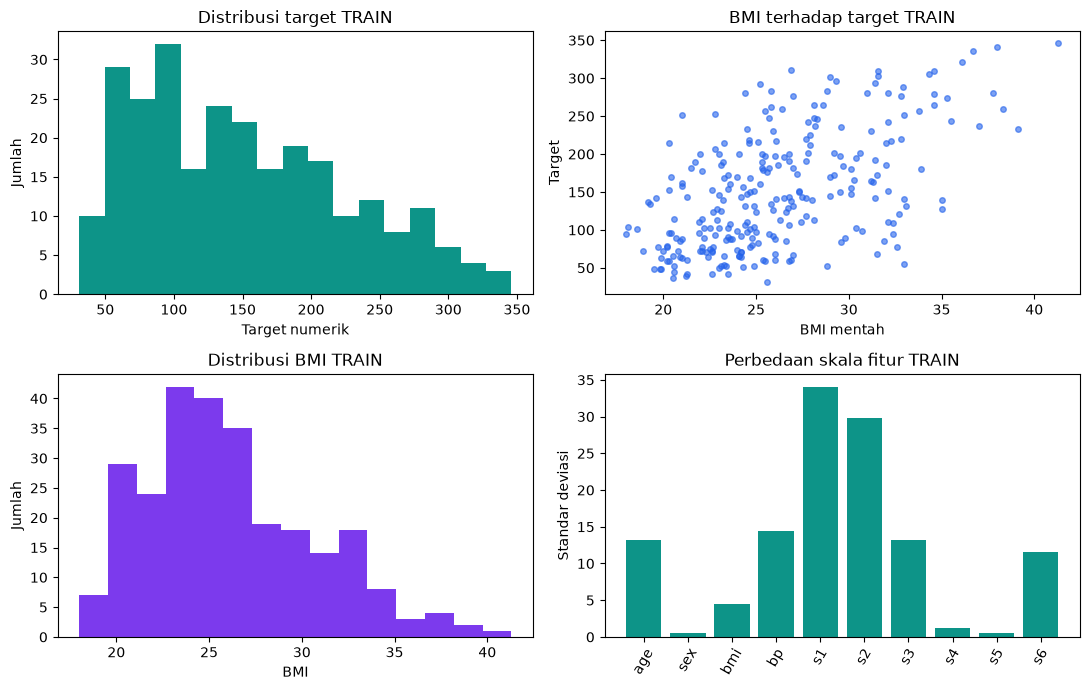

In [5]:
fig,axs=plt.subplots(2,2,figsize=(11,7))
axs[0,0].hist(yr_train,bins=17,color='#0d9488');axs[0,0].set(title='Distribusi target TRAIN',xlabel='Target numerik',ylabel='Jumlah')
axs[0,1].scatter(Xr_train['bmi'],yr_train,s=16,alpha=.6,color='#2563eb');axs[0,1].set(title='BMI terhadap target TRAIN',xlabel='BMI mentah',ylabel='Target')
axs[1,0].hist(Xr_train['bmi'],bins=15,color='#7c3aed');axs[1,0].set(title='Distribusi BMI TRAIN',xlabel='BMI',ylabel='Jumlah')
axs[1,1].bar(Xr_train.std().index, Xr_train.std().values,color='#0d9488');axs[1,1].tick_params(axis='x',rotation=60);axs[1,1].set(title='Perbedaan skala fitur TRAIN',ylabel='Standar deviasi')
plt.tight_layout();plt.show()

**P2 — Audit dan kelayakan Linear Regression**

**✍️ JAWABAN:** Tuliskan (a) 4 temuan numerik EDA (skala, missing, bentuk target, asosiasi BMI), (b) mengapa histogram fitur **tidak** harus normal untuk memakai Linear Regression, (c) mengapa residual dan linearitas hubungan bersyarat lebih relevan daripada histogram fitur, serta (d) risiko outlier dan multikolinearitas.

**(a) Empat temuan numerik EDA (TRAIN, 264 baris):**
1. **Skala sangat beda:** std `s1` = 34,09 dan `s2` = 29,78, sedangkan `s5` = 0,50 dan `sex` = 0,50 (beda ±68×). Satuannya juga campur (umur tahun, BMI kg/m², tekanan darah mmHg, serum).
2. **Missing = 0 dan duplikat = 0** di semua kolom. `sex` cuma punya 2 nilai (1/2), jadi sebenarnya kategorik.
3. **Bentuk target:** rentang 31–346, skew **0,54**, sedikit miring ke kanan (lebih banyak pasien dengan target rendah 50–150).
4. **Asosiasi BMI:** Pearson BMI–target = **0,56**, korelasi terkuat, disusul `s5` 0,525 dan `bp` 0,464. Scatter BMI vs target naik tapi sebarannya lebar, jadi BMI sendiri jelas tidak cukup.

**(b)** Linear Regression (OLS) **tidak mensyaratkan fitur X berdistribusi normal**. Model cuma mencari kombinasi linear fitur yang meminimalkan error kuadrat. BMI yang miring kanan (skew 0,69) atau `sex` yang biner tetap sah jadi fitur.

**(c)** Yang diasumsikan OLS adalah **hubungan target dengan fitur (bersyarat) kurang lebih linear** dan **error/residual** berperilaku baik: tidak berpola, variansnya kira-kira konstan, dan normal kalau mau bikin interval/uji-t. Histogram fitur tidak bilang apa-apa soal hal itu. Yang perlu dicek adalah plot residual vs prediksi setelah model di-fit.

**(d) Risiko:**
- **Outlier:** dengan aturan 1,5×IQR di train ada 9 nilai ekstrem di `s2`, 7 di `s1`, dan 5 di `s3`. OLS memakai error kuadrat, jadi titik ekstrem bisa menarik garis.
- **Multikolinearitas:** `s1`–`s2` berkorelasi **0,899** dan `s3`–`s4` 0,745. VIF (dihitung di train) `s1` ≈ 74,5 dan `s2` ≈ 49,3, jauh di atas batas umum 10. Akibatnya koefisien individual tidak stabil dan susah ditafsirkan (tandanya bisa terbalik), walaupun prediksinya sendiri masih bisa bagus.


## P3 — Baseline dan model regresi: Linear Regression versus KNNRegressor
**Model membandingkan tugas yang sama pada split yang sama:** baseline median, LR 1 fitur BMI, LR seluruh 10 fitur, KNN regresi tanpa/dengan scaling. `LinearRegression.fit()` scikit-learn menghitung solusi least-squares, **bukan** 12 langkah gradient descent di P1. P1 bertujuan menjelaskan konsep optimasi.

In [6]:
models_reg={
    'Dummy median':DummyRegressor(strategy='median'),
    'LinearRegression BMI':LinearRegression(),
    'LinearRegression 10 fitur':LinearRegression(),
    'KNNReg k=5 RAW':KNeighborsRegressor(n_neighbors=5),
    'KNNReg k=5 STD':Pipeline([('scale',StandardScaler()),('knn',KNeighborsRegressor(n_neighbors=5))]),
    'KNNReg k=15 STD':Pipeline([('scale',StandardScaler()),('knn',KNeighborsRegressor(n_neighbors=15))]),
    'KNNReg k=5 Robust':Pipeline([('scale',RobustScaler()),('knn',KNeighborsRegressor(n_neighbors=5))]),
}
reg_results=[];reg_fitted={}
for name,model in models_reg.items():
    features=['bmi'] if name=='LinearRegression BMI' else Xr_train.columns.tolist()
    model.fit(Xr_train[features],yr_train)
    prediction=model.predict(Xr_val[features])
    reg_fitted[name]=(model,features)
    reg_results.append({'model':name,'n_features':len(features),
         'MAE_val':mean_absolute_error(yr_val,prediction),
         'RMSE_val':np.sqrt(mean_squared_error(yr_val,prediction)),
         'R2_val':r2_score(yr_val,prediction)})
reg_table=pd.DataFrame(reg_results).sort_values('RMSE_val').reset_index(drop=True)
display(reg_table.round(3))
print('LR 10 fitur tidak memerlukan y classification; prediksinya angka kontinu.')

,model,n_features,MAE_val,RMSE_val,R2_val
0,LinearRegression 10 fitur,10,46.633,56.201,0.519
1,KNNReg k=15 STD,10,50.360,60.052,0.451
2,LinearRegression BMI,1,54.988,64.741,0.362
3,KNNReg k=5 STD,10,52.175,65.092,0.355
4,KNNReg k=5 Robust,10,53.530,66.118,0.335
5,KNNReg k=5 RAW,10,61.315,73.116,0.186
6,Dummy median,10,69.938,83.202,-0.054


LR 10 fitur tidak memerlukan y classification; prediksinya angka kontinu.


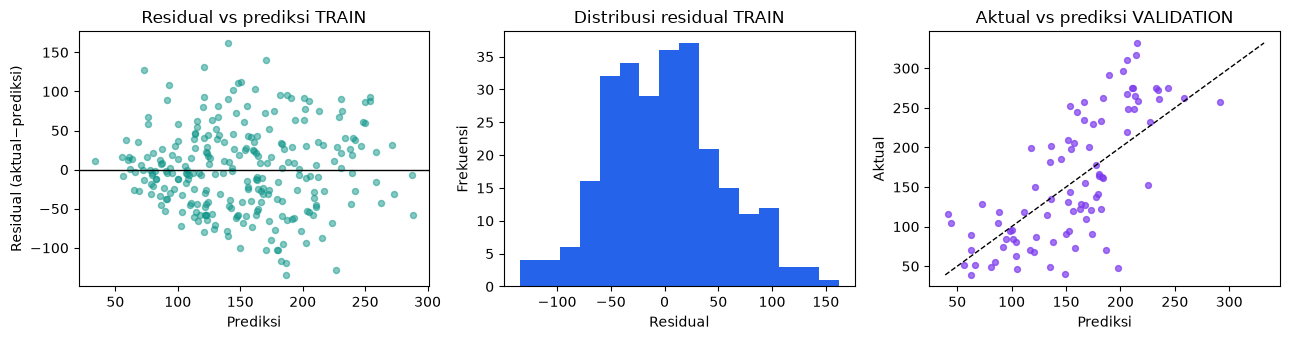

In [7]:
# Residual diagnostics hanya TRAIN/VALIDATION, bukan TEST
lr_model,lr_feats=reg_fitted['LinearRegression 10 fitur']
yhat_train=lr_model.predict(Xr_train[lr_feats]);yhat_val=lr_model.predict(Xr_val[lr_feats])
fig,axs=plt.subplots(1,3,figsize=(13,3.5))
axs[0].scatter(yhat_train,yr_train-yhat_train,alpha=.5,s=19,color='#0d9488');axs[0].axhline(0,color='black',lw=1)
axs[0].set(title='Residual vs prediksi TRAIN',xlabel='Prediksi',ylabel='Residual (aktual−prediksi)')
axs[1].hist(yr_train-yhat_train,bins=16,color='#2563eb');axs[1].set(title='Distribusi residual TRAIN',xlabel='Residual',ylabel='Frekuensi')
axs[2].scatter(yhat_val,yr_val,s=18,alpha=.7,color='#7c3aed');lims=[min(yhat_val.min(),yr_val.min()),max(yhat_val.max(),yr_val.max())]
axs[2].plot(lims,lims,'--',color='black',lw=1);axs[2].set(title='Aktual vs prediksi VALIDATION',xlabel='Prediksi',ylabel='Aktual')
plt.tight_layout();plt.show()

**P3 — Interpretasi hasil regresi**

**✍️ JAWABAN:** Bandingkan MAE/RMSE/R² LR 1 fitur vs 10 fitur vs KNNRegressor; jelaskan kapan scaling mengubah hasil KNN namun tidak banyak mengubah prediksi OLS tanpa regularisasi. Jelaskan setidaknya dua pola atau keterbatasan pada grafik residual.

| Model (VALIDATION, 89 baris) | MAE | RMSE | R² |
|---|---|---|---|
| **LR 10 fitur** | **46,63** | **56,20** | **0,519** |
| KNNReg k=15 STD | 50,36 | 60,05 | 0,451 |
| LR BMI saja | 54,99 | 64,74 | 0,362 |
| KNNReg k=5 STD | 52,18 | 65,09 | 0,355 |
| KNNReg k=5 Robust | 53,53 | 66,12 | 0,335 |
| KNNReg k=5 RAW | 61,32 | 73,12 | 0,186 |
| Dummy median | 69,94 | 83,20 | −0,054 |

- **LR 1 fitur vs 10 fitur:** menambah 9 fitur menurunkan RMSE 64,74 → 56,20 dan menaikkan R² 0,362 → 0,519. Fitur lain (terutama `s5`, `bp`) membawa informasi yang tidak ada di BMI.
- **KNNReg:** yang terbaik k = 15 + StandardScaler (RMSE 60,05), masih kalah dari LR 10 fitur. Semua model mengalahkan baseline median (R² negatif = lebih buruk dari menebak konstan).
- **Scaling:** KNN menghitung jarak Euclidean, jadi tanpa scaling jaraknya didominasi `s1`/`s2` (std ±30) dan fitur kecil seperti `s5`/`bmi` hampir tidak dihitung. Hasilnya RMSE 73,12 (RAW) vs 65,09 (STD) pada k = 5. OLS tanpa regularisasi tidak berubah prediksinya karena scaling cuma mengubah satuan koefisien: koefisien menyesuaikan dan intercept menyerap mean. Aku cek, prediksi LR dengan dan tanpa StandardScaler sama persis (`np.allclose` = True). Kalau pakai Ridge/Lasso baru scaling berpengaruh.

**Pola di grafik residual:**
1. **Ada "batas bawah" diagonal** di residual vs prediksi TRAIN: residual negatif paling besar makin turun saat prediksi naik. Ini karena target tidak pernah di bawah ±31, jadi residual = aktual − prediksi dibatasi dari bawah. Tandanya hubungan tidak sepenuhnya linear/aditif.
2. **Prediksi "terkompres" ke tengah:** di plot aktual vs prediksi VALIDATION, pasien dengan target tinggi (> 250) hampir semua berada di atas garis diagonal (*underestimate*). Prediksi validation cuma 41–292, sedangkan aktualnya 39–332.
3. Residual train cukup simetris (skew 0,21, std 53,6), tapi rentangnya lebar (−135 s.d. +162). R² train 0,496 ≈ R² val 0,519, jadi modelnya **tidak overfit** tapi memang *underfit* karena hubungan aslinya tidak cukup linear/datanya noisy.


## P4 — Ablation fitur, validasi, lalu kunci model regresi
**Ubah satu faktor yang jelas:** LR dengan BMI saja vs BMI+s5 vs 10 fitur; KNNReg raw vs scaled vs nilai k. Metrik utama **RMSE pada validation**, didukung MAE dan R². Setelah memilih satu konfigurasi, buka test satu kali di bagian P9.

In [8]:
extra_reg=[]
for feature_set in [['bmi'],['bmi','s5'],Xr_train.columns.tolist()]:
   m=LinearRegression().fit(Xr_train[feature_set],yr_train)
   pred=m.predict(Xr_val[feature_set])
   extra_reg.append({'fitur':','.join(feature_set) if len(feature_set)<3 else '10 fitur',
      'n':len(feature_set),'RMSE_val':np.sqrt(mean_squared_error(yr_val,pred)),
      'MAE_val':mean_absolute_error(yr_val,pred),'R2_val':r2_score(yr_val,pred)})
display(pd.DataFrame(extra_reg).round(3))
REG_FINAL_NAME=reg_table.iloc[0]['model'] # dapat diganti setelah membaca bukti validation
assert REG_FINAL_NAME in reg_fitted
print('REG_FINAL_NAME terkunci sementara:',REG_FINAL_NAME)
print('Belum mengevaluasi pada test!')

,fitur,n,RMSE_val,MAE_val,R2_val
0,bmi,1,64.741,54.988,0.362
1,"bmi,s5",2,56.155,48.299,0.520
2,10 fitur,10,56.201,46.633,0.519


REG_FINAL_NAME terkunci sementara: LinearRegression 10 fitur
Belum mengevaluasi pada test!


**P4 — Keputusan dan ablation regresi**

**✍️ JAWABAN:** Nyatakan konfigurasi final, alasan EDA, bukti angka validation, dimensi fitur, dan trade-off interpretabilitas. Jangan hanya memilih berdasarkan RMSE terendah jika selisih kecil; bahas biaya dan keterbatasan.

**Konfigurasi final regresi: `LinearRegression 10 fitur`** (semua 10 fitur mentah, tanpa scaling, OLS).

**Bukti validation (ablation LR, satu faktor = set fitur):**
| Fitur | n | RMSE | MAE | R² |
|---|---|---|---|---|
| bmi | 1 | 64,74 | 54,99 | 0,362 |
| bmi + s5 | 2 | **56,16** | 48,30 | **0,520** |
| 10 fitur | 10 | 56,20 | **46,63** | 0,519 |

Jujur saja, **bmi + s5 hampir seri** dengan 10 fitur (RMSE cuma beda 0,05, jauh di bawah noise 89 baris validation). Alasan aku tetap kunci 10 fitur:
1. MAE-nya lebih baik ±1,7 poin, artinya error tipikal per pasien lebih kecil.
2. Ini kandidat yang memang ada di daftar pembanding P3 (`reg_fitted`) dan RMSE-nya terendah di sana, jadi pilihannya konsisten dengan aturan yang ditetapkan sebelum melihat test.
3. Dari EDA, `bp`, `s4`, dan `s3` juga berkorelasi lumayan dengan target (0,46; 0,40; −0,36), jadi masuk akal ikut dipakai. R² train 0,496 vs val 0,519 juga menunjukkan 10 fitur tidak bikin overfit.

**Trade-off:** model 2 fitur (bmi + s5) jauh lebih **interpretable** dan murah (cuma butuh 2 ukuran), plus bebas dari masalah multikolinearitas `s1`–`s2` (VIF ±74) yang bikin koefisien 10 fitur susah dibaca satu per satu. Kalau tujuannya penjelasan ke orang awam, aku pilih bmi + s5. Karena tujuan praktikum ini akurasi prediksi angka, aku ambil 10 fitur. KNNReg tidak dipilih karena RMSE terbaiknya (60,05) masih lebih buruk dan prediksinya lebih susah dijelaskan.


## P5 — Dataset Iris untuk **KNN KLASIFIKASI**
Iris terdiri atas 150 observasi biologis dengan 4 fitur ukuran bunga (cm) dan **label target spesies** dalam 3 kelas. Ini supervised learning. **Tujuan:** menjelaskan mengapa titik baru diklasifikasikan berdasarkan tetangga terdekat, bukan berdasarkan centroid cluster.

KNN tidak mempunyai iterasi gradient descent seperti LR. Model `fit()` menyimpan data latih; pada **dua kasus prediksi Q1 dan Q2** di bawah, kita melakukan jarak → urut tetangga → voting untuk k=1,3,5. Kedua kasus memakai baris nyata Iris dan 10 referensi nyata yang dipilih untuk *worked example*, bukan untuk skor model akhir.

In [9]:
iris=load_iris(as_frame=True)
iris_df=iris.frame.copy(); iris_df.index.name='row_id'
iris_df['species_name']=iris_df['target'].map({i:n for i,n in enumerate(iris.target_names)})
print('Kelas:',list(iris.target_names),'| total:',len(iris_df))
display(iris_df.head())
print('Distribusi 3 kelas:',iris_df['species_name'].value_counts().to_dict())

Kelas: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')] | total: 150


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species_name
row_id,,,,,,
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


Distribusi 3 kelas: {np.str_('setosa'): 50, np.str_('versicolor'): 50, np.str_('virginica'): 50}


### P5A — Dua kasus prediksi manual dari observasi Iris asli
**DATA REFERENSI**: indeks 50, 56, 63, 77, 83, 101, 106, 119, 123, 126. **TITIK BARU**: Q1=baris asli 52 dan Q2=baris asli 129 (untuk latihan, jangan ikutkan kedua query dalam set referensi). Fitur jarak `petal length`, `petal width`, dalam cm. Hitung semuanya dengan `d² = Δlength² + Δwidth²`, lalu akar. Bandingkan label k=1,3,5.

10 referensi nyata untuk manual:


,petal length (cm),petal width (cm),species_name
row_id,,,
50,4.7,1.4,versicolor
56,4.7,1.6,versicolor
63,4.7,1.4,versicolor
77,5.0,1.7,versicolor
83,5.1,1.6,versicolor
101,5.1,1.9,virginica
106,4.5,1.7,virginica
119,5.0,1.5,virginica
123,4.9,1.8,virginica



Query row_id=52, (petal length, petal width)=[4.9, 1.5], actual label=versicolor


,petal length (cm),petal width (cm),species_name,distance
row_id,,,,
119,5.0,1.5,virginica,0.1000
83,5.1,1.6,versicolor,0.2236
77,5.0,1.7,versicolor,0.2236
50,4.7,1.4,versicolor,0.2236
56,4.7,1.6,versicolor,0.2236
63,4.7,1.4,versicolor,0.2236
123,4.9,1.8,virginica,0.3000
126,4.8,1.8,virginica,0.3162
101,5.1,1.9,virginica,0.4472


 k=1: voting={np.str_('virginica'): 1} → prediksi virginica
 k=3: voting={np.str_('versicolor'): 2, np.str_('virginica'): 1} → prediksi versicolor
 k=5: voting={np.str_('versicolor'): 4, np.str_('virginica'): 1} → prediksi versicolor

Query row_id=129, (petal length, petal width)=[5.8, 1.6], actual label=virginica


,petal length (cm),petal width (cm),species_name,distance
row_id,,,,
83,5.1,1.6,versicolor,0.7000
101,5.1,1.9,virginica,0.7616
77,5.0,1.7,versicolor,0.8062
119,5.0,1.5,virginica,0.8062
123,4.9,1.8,virginica,0.9220
126,4.8,1.8,virginica,1.0198
56,4.7,1.6,versicolor,1.1000
50,4.7,1.4,versicolor,1.1180
63,4.7,1.4,versicolor,1.1180


 k=1: voting={np.str_('versicolor'): 1} → prediksi versicolor
 k=3: voting={np.str_('versicolor'): 2, np.str_('virginica'): 1} → prediksi versicolor
 k=5: voting={np.str_('virginica'): 3, np.str_('versicolor'): 2} → prediksi virginica


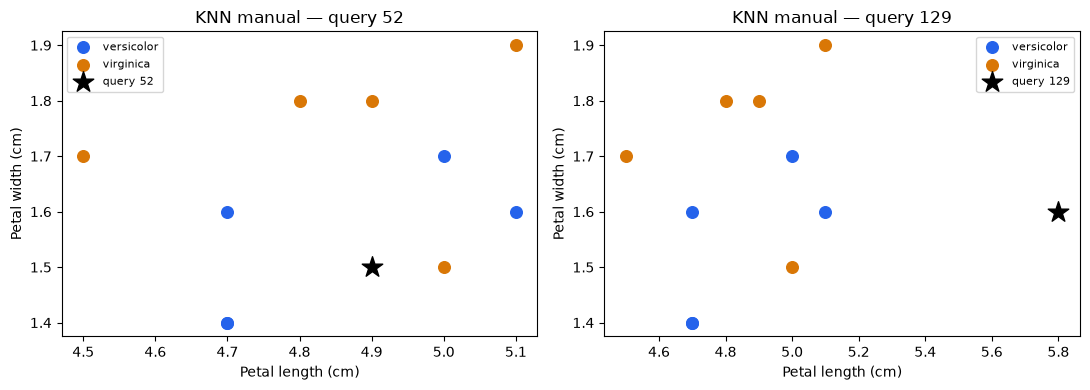

In [10]:
ref_ids=[50,56,63,77,83,101,106,119,123,126]
query_ids=[52,129]
manual_cols=['petal length (cm)','petal width (cm)']
reference=iris_df.loc[ref_ids,manual_cols+['species_name']]
print('10 referensi nyata untuk manual:')
display(reference)
for query_id in query_ids:
    q=iris_df.loc[query_id,manual_cols].to_numpy(dtype=float)
    calc=reference.copy()
    calc['distance']=np.sqrt(((calc[manual_cols]-q)**2).sum(axis=1))
    calc=calc.sort_values('distance',kind='stable')
    print(f'\nQuery row_id={query_id}, (petal length, petal width)={q.tolist()}, actual label={iris_df.loc[query_id,"species_name"]}')
    display(calc.round(4))
    for k in [1,3,5]:
        neighbors=calc.head(k)['species_name']
        counts=neighbors.value_counts().to_dict()
        predicted=neighbors.value_counts().idxmax()
        print(f' k={k}: voting={counts} → prediksi {predicted}')
fig,axs=plt.subplots(1,2,figsize=(11,4))
colors={'setosa':'#0d9488','versicolor':'#2563eb','virginica':'#d97706'}
for ax,qi in zip(axs,query_ids):
    for label,g in reference.groupby('species_name'):
        ax.scatter(g[manual_cols[0]],g[manual_cols[1]],label=label,s=70,color=colors[label])
    ax.scatter(iris_df.loc[qi,manual_cols[0]],iris_df.loc[qi,manual_cols[1]],marker='*',s=240,color='black',label=f'query {qi}')
    ax.set(title=f'KNN manual — query {qi}',xlabel='Petal length (cm)',ylabel='Petal width (cm)');ax.legend(fontsize=8)
plt.tight_layout();plt.show()

**P5 — Dua contoh klasifikasi manual**

**✍️ JAWABAN:** Untuk Q1 dan Q2, tunjukkan 5 tetangga terdekat beserta jaraknya, label asli, hasil voting pada k=1/3/5, dan mengapa perubahan k dapat memperbaiki atau memperburuk prediksi. Jelaskan ini bukan “iterasi training” KNN.

**Q1 = ID 52, (4,9; 1,5), asli versicolor**

| Urutan | ID | (length, width) | Label | Jarak |
|---|---|---|---|---|
| 1 | 119 | (5,0; 1,5) | virginica | √(0,1² + 0²) = **0,1000** |
| 2 | 83 | (5,1; 1,6) | versicolor | √(0,2² + 0,1²) = **0,2236** |
| 3 | 77 | (5,0; 1,7) | versicolor | √(0,1² + 0,2²) = 0,2236 |
| 4 | 50 | (4,7; 1,4) | versicolor | √(0,2² + 0,1²) = 0,2236 |
| 5 | 56 | (4,7; 1,6) | versicolor | 0,2236 |

- k = 1 → {virginica: 1} → **virginica ✘**
- k = 3 → {versicolor 2, virginica 1} → **versicolor ✔**
- k = 5 → {versicolor 4, virginica 1} → **versicolor ✔**

Catatan: ada 5 referensi seri di jarak 0,2236 (83, 77, 50, 56, 63), semuanya versicolor. Siapa pun yang terpilih, hasil voting-nya tetap sama.

**Q2 = ID 129, (5,8; 1,6), asli virginica**

| Urutan | ID | (length, width) | Label | Jarak |
|---|---|---|---|---|
| 1 | 83 | (5,1; 1,6) | versicolor | √(0,7² + 0²) = **0,7000** |
| 2 | 101 | (5,1; 1,9) | virginica | √(0,49 + 0,09) = **0,7616** |
| 3 | 77 | (5,0; 1,7) | versicolor | √(0,64 + 0,01) = **0,8062** |
| 4 | 119 | (5,0; 1,5) | virginica | √(0,64 + 0,01) = 0,8062 |
| 5 | 123 | (4,9; 1,8) | virginica | √(0,81 + 0,04) = **0,9220** |

- k = 1 → versicolor ✘; k = 3 → {versicolor 2, virginica 1} → versicolor ✘; k = 5 → {virginica 3, versicolor 2} → **virginica ✔**

**Kenapa k mengubah hasil:** k = 1 sangat sensitif ke satu tetangga yang kebetulan paling dekat. Di Q1, ID 119 (virginica) nyelip di tengah kelompok versicolor, jadi prediksinya salah. Menaikkan k menambah "suara" sehingga noise lokal tertutup oleh mayoritas (variance turun). Di Q2, titik query ada di pinggir (length 5,8 lebih besar dari semua referensi), sehingga butuh k = 5 baru mayoritas virginica muncul. Bahkan di k = 3 ada seri jarak 0,8062 antara ID 77 (V) dan 119 (G); urutan saja yang menentukan prediksinya V. Kebalikannya, k yang terlalu besar bisa menarik tetangga jauh dari kelas lain (bias naik). Jadi k harus dipilih lewat validation.

**Ini bukan "iterasi training":** KNN adalah *lazy learner*. `fit()` cuma menyimpan data referensi, tidak ada w/b yang di-update dan tidak ada loss yang diturunkan seperti di P1. Semua kerjaan (hitung jarak → urutkan → voting) baru terjadi saat **prediksi**, dan diulang untuk setiap query baru.


## P6 — Split Iris, EDA train-only, uji kelayakan KNN
**Kapan KNN layak dicoba?** Ketika kedekatan fitur mempunyai makna, dimensi relatif rendah/terkelola, pola lokal relevan, data training cukup mewakili variasi kelas. **Normalitas setiap fitur bukan syarat KNN**. Iris mempunyai kelas seimbang 50/50/50 dan pengukuran numerik, tetapi sebagian kelas saling tumpang-tindih menurut fitur yang dipilih.

Lakukan stratified split lebih dahulu dan periksa data TRAIN saja.

In [11]:
Xc=iris_df.drop(columns=['target','species_name']);yc=iris_df['target']
Xc_trainval,Xc_test,yc_trainval,yc_test=train_test_split(Xc,yc,test_size=.20,random_state=SEED,stratify=yc)
Xc_train,Xc_val,yc_train,yc_val=train_test_split(Xc_trainval,yc_trainval,test_size=.25,random_state=SEED,stratify=yc_trainval)
train_cls=Xc_train.copy();train_cls['species']=yc_train.map({i:n for i,n in enumerate(iris.target_names)})
print('train / validation / test:',len(Xc_train),len(Xc_val),len(Xc_test))
print('missing TRAIN:',int(train_cls.isna().sum().sum()),'duplicates train:',int(train_cls.duplicated().sum()))
print('kelas TRAIN:',train_cls['species'].value_counts().to_dict())
display(Xc_train.describe().round(2))

train / validation / test: 90 30 30
missing TRAIN: 0 duplicates train: 0
kelas TRAIN: {np.str_('setosa'): 30, np.str_('virginica'): 30, np.str_('versicolor'): 30}


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,90.00,90.00,90.00,90.00
mean,5.86,3.08,3.79,1.21
std,0.84,0.42,1.80,0.77
min,4.40,2.00,1.00,0.10
25%,5.10,2.80,1.52,0.30
50%,5.70,3.00,4.45,1.35
75%,6.40,3.38,5.10,1.80
max,7.70,4.40,6.90,2.50


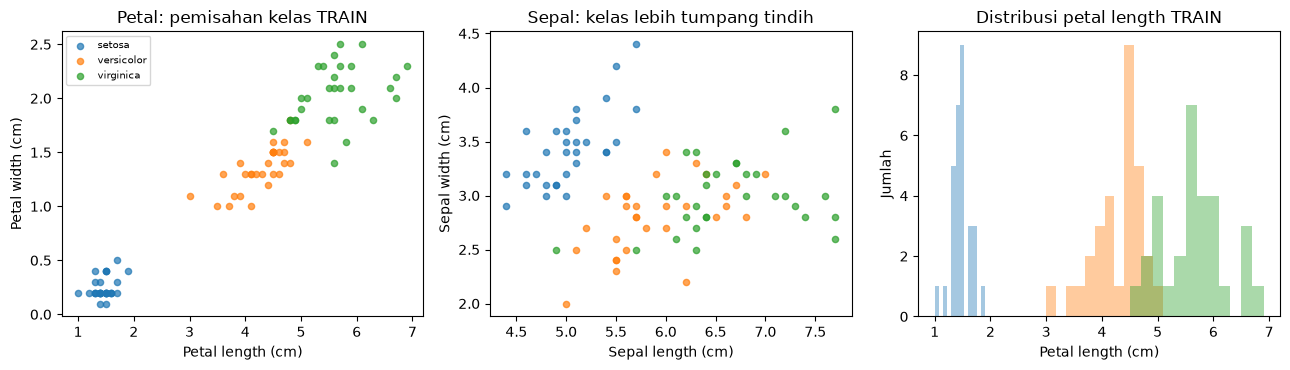

In [12]:
fig,axs=plt.subplots(1,3,figsize=(13,3.8))
for n,g in train_cls.groupby('species'):
    axs[0].scatter(g['petal length (cm)'],g['petal width (cm)'],alpha=.7,s=20,label=n)
    axs[1].scatter(g['sepal length (cm)'],g['sepal width (cm)'],alpha=.7,s=20,label=n)
    axs[2].hist(g['petal length (cm)'],bins=12,alpha=.4,label=n)
axs[0].set(title='Petal: pemisahan kelas TRAIN',xlabel='Petal length (cm)',ylabel='Petal width (cm)')
axs[1].set(title='Sepal: kelas lebih tumpang tindih',xlabel='Sepal length (cm)',ylabel='Sepal width (cm)')
axs[2].set(title='Distribusi petal length TRAIN',xlabel='Petal length (cm)',ylabel='Jumlah')
axs[0].legend(fontsize=7);plt.tight_layout();plt.show()

**P6 — Audit kesiapan KNN klasifikasi**

**✍️ JAWABAN:** Sebutkan statistik balance tiga kelas train, missing/duplikat, fitur dengan separasi visual lebih jelas, kemungkinan overlap, mengapa KNN tidak memerlukan distribusi normal dan mengapa tetap perlu scaling serta test yang dipisah.

- **Balance kelas TRAIN:** setosa 30, versicolor 30, virginica 30 (90 baris, persis 1/3 masing-masing berkat `stratify`). Validation dan test masing-masing 30 (10 per kelas). Baseline mayoritas jadi lemah: Macro-F1 cuma **0,167**.
- **Missing = 0, duplikat TRAIN = 0.**
- **Separasi visual:** fitur **petal** paling jelas. Setosa terpisah total (petal length ≤ 1,9 cm, width ≤ 0,5 cm). Di sepal, ketiga kelas saling tumpang-tindih, terutama versicolor–virginica.
- **Overlap:** versicolor (petal width 1,0–1,8, length sampai 5,1) dan virginica (width mulai 1,4) bertumpuk di daerah **length ±4,5–5,1 cm dan width ±1,4–1,8 cm**. Di situlah KNN paling mungkin salah karena tetangganya campur.
- **Kenapa tidak perlu normal:** KNN *non-parametrik*. Tidak ada asumsi bentuk distribusi, keputusannya cuma pakai jarak ke tetangga. Histogram petal length train juga jelas bimodal (setosa terpisah), dan itu tidak masalah buat KNN.
- **Kenapa tetap perlu scaling:** jarak Euclidean langsung menjumlahkan selisih tiap fitur. Std petal length 1,80 cm vs sepal width 0,42 cm (±4×), jadi tanpa scaling fitur ber-rentang besar lebih "berkuasa". Di Iris efeknya kecil karena satuannya sama-sama cm, tapi kebiasaan ini penting (di Diabetes efeknya besar).
- **Kenapa test dipisah:** kalau k, fitur, atau scaler dipilih sambil lihat test, skor test jadi bias optimis (leakage). Scaler juga harus di-fit di train saja (lewat Pipeline).


## P7 — Ablation KNN classification: k, scaling, pemilihan fitur
Gunakan split yang sama untuk seluruh run: (a) empat fitur, (b) hanya sepal, (c) hanya petal; scaler `none` vs `StandardScaler`; nilai k = 1,3,5,9,15. Gunakan **Macro-F1 validation** sebagai metrik utama dan balanced accuracy pendamping. Tidak melakukan resampling karena kelas asli seimbang.

In [13]:
# Baseline klasifikasi disiapkan sebelum memilih KNN.
dummy=DummyClassifier(strategy='most_frequent')
dummy.fit(Xc_train,yc_train)
base_pred=dummy.predict(Xc_val)
print('Baseline mayoritas: Macro-F1 validation =',round(f1_score(yc_val,base_pred,average='macro'),3))
print('Balance kelas train:',yc_train.value_counts().sort_index().to_dict())

Baseline mayoritas: Macro-F1 validation = 0.167
Balance kelas train: {0: 30, 1: 30, 2: 30}


,run,features,scaler,k,macro_F1_val,balanced_acc_val,accuracy_val
0,all4 | none | k=1,all4,none,1,1.000,1.000,1.000
1,petal2 | none | k=1,petal2,none,1,1.000,1.000,1.000
2,petal2 | standard | k=1,petal2,standard,1,1.000,1.000,1.000
3,all4 | none | k=3,all4,none,3,1.000,1.000,1.000
4,all4 | standard | k=3,all4,standard,3,1.000,1.000,1.000
5,all4 | none | k=5,all4,none,5,1.000,1.000,1.000
6,all4 | standard | k=5,all4,standard,5,1.000,1.000,1.000
7,all4 | none | k=9,all4,none,9,1.000,1.000,1.000
8,all4 | standard | k=9,all4,standard,9,1.000,1.000,1.000
9,all4 | none | k=15,all4,none,15,1.000,1.000,1.000


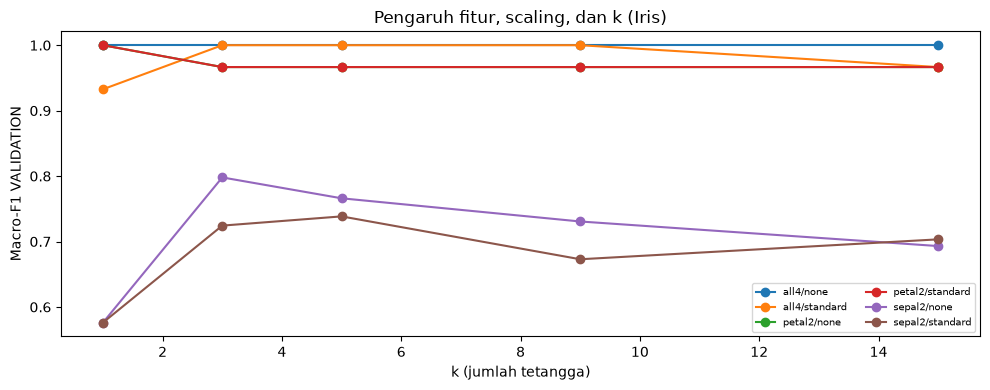

In [14]:
feature_sets={'all4':Xc_train.columns.tolist(),
              'sepal2':['sepal length (cm)','sepal width (cm)'],
              'petal2':['petal length (cm)','petal width (cm)']}
cls_runs=[];cls_fitted={}
for set_name,feature_cols in feature_sets.items():
 for scaler_name in ['none','standard']:
  for k in [1,3,5,9,15]:
   clf=(KNeighborsClassifier(n_neighbors=k) if scaler_name=='none' else
        Pipeline([('scale',StandardScaler()),('knn',KNeighborsClassifier(n_neighbors=k))]))
   clf.fit(Xc_train[feature_cols],yc_train)
   yp=clf.predict(Xc_val[feature_cols])
   name=f'{set_name} | {scaler_name} | k={k}'
   cls_fitted[name]=(clf,feature_cols)
   cls_runs.append({'run':name,'features':set_name,'scaler':scaler_name,'k':k,
        'macro_F1_val':f1_score(yc_val,yp,average='macro'),
        'balanced_acc_val':balanced_accuracy_score(yc_val,yp),
        'accuracy_val':accuracy_score(yc_val,yp)})
cls_table=pd.DataFrame(cls_runs).sort_values(['macro_F1_val','k'],ascending=[False,True]).reset_index(drop=True)
display(cls_table.head(15).round(3))
fig,ax=plt.subplots(figsize=(10,4))
for (feature,scale),grp in pd.DataFrame(cls_runs).groupby(['features','scaler']):
   ax.plot(grp['k'],grp['macro_F1_val'],marker='o',label=f'{feature}/{scale}')
ax.set(xlabel='k (jumlah tetangga)',ylabel='Macro-F1 VALIDATION',title='Pengaruh fitur, scaling, dan k (Iris)');ax.legend(fontsize=7,ncol=2)
plt.tight_layout();plt.show()

### P7B — Ablation feature extraction PCA (dari pertemuan 6)
Bandingkan KNN pada semua fitur asli yang distandardisasi dengan KNN pada **2 principal components**. Semua transformasi PCA harus di-fit di dalam Pipeline menggunakan data TRAIN. Perubahan skala dan dimensi tidak otomatis membuat kinerja lebih baik. Periksa explained variance ratio dan Macro-F1 di validation.

In [15]:
from sklearn.decomposition import PCA
pca_clf=Pipeline([('scale',StandardScaler()),('pca',PCA(n_components=2)),
                  ('knn',KNeighborsClassifier(n_neighbors=5))])
pca_clf.fit(Xc_train,yc_train)
pca_pred=pca_clf.predict(Xc_val)
pca_evr=pca_clf.named_steps['pca'].explained_variance_ratio_
print('PCA EVR komponen 1/2:',np.round(pca_evr,4),
      '| cumulative=',round(float(pca_evr.sum()),4))
print('KNN k=5 + PCA(2) F1 validation:',round(f1_score(yc_val,pca_pred,average='macro'),4))
print('KNN k=5 + all4 STD F1 validation:',round(float(pd.DataFrame(cls_runs).query("features == 'all4' and scaler == 'standard' and k == 5").iloc[0]['macro_F1_val']),4))

PCA EVR komponen 1/2: [0.7308 0.2276] | cumulative= 0.9583
KNN k=5 + PCA(2) F1 validation: 0.9327
KNN k=5 + all4 STD F1 validation: 1.0


### P7C — Pengayaan Logistic Regression: dari probabilitas ke klasifikasi

**Kenapa perlu ditambahkan?** Linear Regression menghasilkan **angka numerik**, Logistic Regression menghasilkan **peluang kelas**, sedangkan KNNClassifier memakai voting tetangga. Pada Iris penuh (3 spesies), Logistic Regression menggunakan **probabilitas multikelas softmax**, bukan aturan threshold biner 0,50 untuk setiap kelas.

**Ilustrasi biner dari baris Iris nyata:** ID 52: petal length 4,9 cm, **versicolor (y=0)**; ID 129: 5,8 cm, **virginica (y=1)**. Gunakan koefisien ilustrasi **w=2, b=−10,5**, lalu hitung z=wx+b, sigmoid, prediksi threshold=0,5, dan Log Loss tiap titik. Koefisien contoh ini **bukan hasil fit**. Jawab dahulu secara manual sebelum menjalankan cell berikut.

In [16]:
# Dua prediksi BINARY secara manual: angka w dan b adalah ASUMSI untuk ilustrasi
import numpy as np
from sklearn.metrics import log_loss
manual_ids=[52,129]
manual_x=iris_df.loc[manual_ids,'petal length (cm)'].to_numpy(dtype=float)
manual_y=(iris_df.loc[manual_ids,'target']==2).astype(int).to_numpy()  # ID 52=0, ID 129=1
assert manual_y.tolist()==[0,1]
w_demo,b_demo=2.0,-10.5
z_demo=w_demo*manual_x+b_demo
prob_demo=1/(1+np.exp(-z_demo))
loss_demo=-(manual_y*np.log(prob_demo)+(1-manual_y)*np.log(1-prob_demo))
manual_log=pd.DataFrame({'row_id':manual_ids,'petal_length_cm':manual_x,'y_virginica':manual_y,
    'skor_z':z_demo,'P_virginica':prob_demo,'prediksi_biner':(prob_demo>=0.5).astype(int),'BCE':loss_demo})
display(manual_log.round(4))
print('Log Loss rata-rata dua titik:',round(float(loss_demo.mean()),4))
assert np.allclose(prob_demo,[0.3318122278,0.7502601056],atol=1e-8)


,row_id,petal_length_cm,y_virginica,skor_z,P_virginica,prediksi_biner,BCE
0,52,4.9,0,-0.7,0.3318,0,0.4032
1,129,5.8,1,1.1,0.7503,1,0.2873


Log Loss rata-rata dua titik: 0.3453


**✍️ JAWABAN P7C-1 — Hitung sebelum melihat output:**

1. Tulis langkah z dan sigmoid untuk kedua baris Iris (ID 52 dan 129).
2. Hitung Binary Cross-Entropy untuk masing-masing label asli dan rata-rata dua titik.
3. Jika threshold berubah dari 0,50 menjadi 0,80, mana prediksi yang berubah? Apakah threshold sebaiknya dipilih menggunakan TEST?
4. Mengapa nilai 0,7503 adalah **probabilitas kelas positif** dalam ilustrasi Logistic Regression, sedangkan prediksi Linear Regression bukan probabilitas?

**JAWABAN MAHASISWA:**

1. **z dan sigmoid** (w = 2, b = −10,5):
   - ID 52 (x = 4,9): z = 2(4,9) − 10,5 = **−0,7**; p = 1/(1 + e^0,7) = 1/(1 + 2,0138) = **0,3318** → p < 0,5 → prediksi **0 (versicolor) ✔**
   - ID 129 (x = 5,8): z = 2(5,8) − 10,5 = **1,1**; p = 1/(1 + e^−1,1) = 1/(1 + 0,3329) = **0,7503** → prediksi **1 (virginica) ✔**
2. **Binary Cross-Entropy** BCE = −[y·ln p + (1 − y)·ln(1 − p)]:
   - ID 52 (y = 0): −ln(1 − 0,3318) = −ln(0,6682) = **0,4032**
   - ID 129 (y = 1): −ln(0,7503) = **0,2873**
   - Rata-rata = (0,4032 + 0,2873)/2 = **0,3453** (sama dengan output)
3. **Threshold 0,80:** ID 52 tetap 0 (0,3318 < 0,8). **ID 129 berubah jadi 0** karena 0,7503 < 0,8, sehingga prediksinya jadi salah. Threshold **tidak boleh dipilih pakai TEST**. Pilih pakai validation (atau CV) sesuai biaya kesalahan (misalnya lebih takut false negative), lalu test cuma untuk laporan akhir.
4. Sigmoid memetakan skor z ke rentang **(0, 1)**, dan modelnya dilatih dengan Log Loss yang memang memperlakukan output sebagai P(y = 1 | x). Jadi 0,7503 bisa dibaca sebagai "peluang virginica ±75% menurut model ini". Prediksi Linear Regression cuma angka kontinu tanpa batas: bisa negatif atau > 1, dan tidak dilatih untuk mencocokkan peluang. Jadi angkanya bukan probabilitas. (Catatan: koefisien di sini asumsi, jadi peluangnya juga cuma ilustrasi.)

### P7C-2 — Verifikasi dua pembaruan gradien Log Loss (pengayaan opsional)

Agar menghubungkan materi gradient descent P2 dengan klasifikasi, gunakan dua pengamatan yang sama dan fitur yang dipusatkan **u=petal_length−5**, sehingga `u=[−0,1; 0,8]`, label `[0,1]`. Mulai `w=b=0`, `learning_rate=0,5`.

Rumus: `grad_w=mean((p−y)×u)`; `grad_b=mean(p−y)`; `w←w−α grad_w`, `b←b−α grad_b`. Bila mengikuti pengayaan, dua iterasi pertama **sebaiknya dihitung dahulu di atas kertas**, lalu verifikasi dengan Python. Hasil ini bukan training model akhir untuk prediksi Iris 3 kelas.

In [17]:
# Dua update awal Logistic Regression biner secara numerik
u=np.array([-0.1,0.8]); y_binary=np.array([0.,1.])
w,b=0.0,0.0; lr=0.5; gradient_rows=[]
for step in range(3):
    probs=1/(1+np.exp(-(w*u+b)))
    ce=-(y_binary*np.log(probs)+(1-y_binary)*np.log(1-probs)).mean()
    grad_w=np.mean((probs-y_binary)*u)
    grad_b=np.mean(probs-y_binary)
    gradient_rows.append({'iterasi':step,'w_sebelum':w,'b_sebelum':b,
                          'p_u_negatif':probs[0],'p_u_positif':probs[1],
                          'LogLoss':ce,'grad_w':grad_w,'grad_b':grad_b})
    w-=lr*grad_w; b-=lr*grad_b
log_gradient=pd.DataFrame(gradient_rows)
display(log_gradient.round(5))
assert np.isclose(log_gradient.loc[0,'grad_w'],-0.225)
assert np.isclose(log_gradient.loc[1,'w_sebelum'],0.1125)
assert np.isclose(log_gradient.loc[2,'w_sebelum'],0.2204327233)


,iterasi,w_sebelum,b_sebelum,p_u_negatif,p_u_positif,LogLoss,grad_w,grad_b
0,0,0.00000,0.00000,0.50000,0.50000,0.69315,-0.22500,0.00000
1,1,0.11250,0.00000,0.49719,0.52248,0.66835,-0.21587,0.00984
2,2,0.22043,-0.00492,0.49326,0.54275,0.64543,-0.20756,0.01801


**✍️ JAWABAN P7C-2 (pengayaan):** Jelaskan mengapa kedua probabilitas awal 0,5, tunjukkan `grad_w` dan `grad_b` iterasi 0–1 secara manual, serta jelaskan mengapa *Log Loss* berkurang pada dua pembaruan awal. Apakah dua baris cukup untuk menyimpulkan performa pada 150 sampel Iris?

**Kenapa awalnya 0,5:** w = b = 0, jadi z = 0·u + 0 = 0 untuk kedua titik, dan sigmoid(0) = 1/(1 + e⁰) = **0,5**. Model belum punya informasi apa-apa.

**Iterasi 0** (u = [−0,1; 0,8], y = [0, 1], p = [0,5; 0,5]): p − y = [0,5; −0,5]
- grad_w = mean([0,5·(−0,1); −0,5·0,8]) = mean([−0,05; −0,40]) = **−0,225**
- grad_b = mean([0,5; −0,5]) = **0**
- w = 0 − 0,5·(−0,225) = **0,1125**; b = 0 − 0 = **0**. LogLoss = −ln(0,5) = **0,69315**

**Iterasi 1** (w = 0,1125, b = 0): z = [−0,01125; 0,09], jadi p = [**0,49719**; **0,52248**] dan p − y = [0,49719; −0,47752]
- grad_w = mean([0,49719·(−0,1); −0,47752·0,8]) = mean([−0,04972; −0,38202]) = **−0,21587**
- grad_b = mean([0,49719; −0,47752]) = **0,00984**
- w = 0,1125 + 0,5·0,21587 = **0,22043**; b = 0 − 0,5·0,00984 = **−0,00492** (sama dengan assert 0,2204327)

**Kenapa Log Loss turun** (0,69315 → 0,66835 → 0,64543): setiap update bergerak berlawanan arah gradien dengan langkah kecil (α = 0,5). Akibatnya p titik positif naik (0,5 → 0,522 → 0,543) dan p titik negatif turun (0,5 → 0,497 → 0,493). Dua-duanya bikin −ln(p benar) mengecil.

**Cukup tidak?** Tidak. Dua baris cuma membuktikan mekanisme update-nya benar. Ini juga kasus biner (versicolor vs virginica) dengan satu fitur, sedangkan Iris asli 150 sampel, 3 kelas, 4 fitur, dan ada setosa. Performa harus diukur pakai model yang di-fit di train dan dievaluasi di validation/test (P7D, P9).


### P7D — Pembanding adil KNNClassifier vs Logistic Regression pada **Iris tiga kelas**

Sekarang **jangan** memakai koefisien ilustrasi tadi. Latih Logistic Regression multikelas yang sesungguhnya pada `Xc_train`, evaluasi pada `Xc_val`, dan gunakan **fitur, preprocessing, split, serta Macro-F1 yang sebanding** dengan KNN. Uji satu ablation fitur/scaling yang terkontrol; `C=1.0` (regularisasi) dan `max_iter=2000` dibuat tetap.

Model Iris tiga kelas memakai probabilitas per kelas yang jumlahnya 1 (**softmax**). Prediksi adalah kelas dengan probabilitas terbesar, bukan threshold 0,5 pada setiap kelas. Nilai pada validation dapat digunakan memilih kandidat; TEST tidak boleh dipakai mengubah keputusan.

Logistic Regression, tiga kelas (VALIDATION):

,run,macro_F1_val,LogLoss_val,balanced_acc_val,accuracy_val
0,LogReg | all4 | standard | C=1,0.9666,0.1552,0.9667,0.9667
1,LogReg | petal2 | standard | C=1,0.9666,0.1695,0.9667,0.9667
2,LogReg | all4 | none | C=1,0.9666,0.1436,0.9667,0.9667


KNN vs Logistic: fitur all4 + StandardScaler (VALIDATION):


,run,macro_F1_val,balanced_acc_val,accuracy_val
6,all4 | standard | k=5,1.0000,1.0000,1.0000
11,LogReg | all4 | standard | C=1,0.9666,0.9667,0.9667


Probabilitas contoh validation: {np.str_('setosa'): np.float64(0.0999), np.str_('versicolor'): np.float64(0.8876), np.str_('virginica'): np.float64(0.0126)} jumlah= 1.0 | prediksi= versicolor


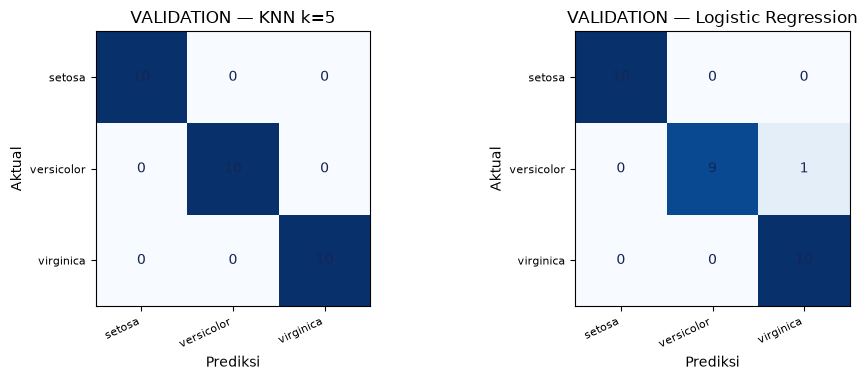

In [18]:
# Perbandingan Logistic Regression vs KNN, TRAIN dan VALIDATION sama
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
logreg_specs=[('all4','standard'),('petal2','standard'),('all4','none')]
logreg_results=[]
for feature_key,scale_key in logreg_specs:
    selected_cols=feature_sets[feature_key]
    steps=[]
    if scale_key=='standard': steps.append(('scale',StandardScaler()))
    steps.append(('logistic',LogisticRegression(C=1.0,max_iter=2000,random_state=SEED)))
    model_log=Pipeline(steps)
    model_log.fit(Xc_train[selected_cols],yc_train)
    predicted=model_log.predict(Xc_val[selected_cols]);probabilities=model_log.predict_proba(Xc_val[selected_cols])
    run_name=f'LogReg | {feature_key} | {scale_key} | C=1'
    score=f1_score(yc_val,predicted,average='macro')
    result={'run':run_name,'features':feature_key,'scaler':scale_key,'k':np.nan,
            'macro_F1_val':score,'balanced_acc_val':balanced_accuracy_score(yc_val,predicted),
            'accuracy_val':accuracy_score(yc_val,predicted),
            'LogLoss_val':log_loss(yc_val,probabilities,labels=model_log.classes_)}
    logreg_results.append(result)
    cls_fitted[run_name]=(model_log,selected_cols)
    cls_runs.append(result)
cls_table=pd.DataFrame(cls_runs).sort_values(['macro_F1_val','run'],ascending=[False,True]).reset_index(drop=True)
logreg_table=pd.DataFrame(logreg_results)
print('Logistic Regression, tiga kelas (VALIDATION):')
display(logreg_table[['run','macro_F1_val','LogLoss_val','balanced_acc_val','accuracy_val']].round(4))
knn_comparison=cls_table[cls_table['run'].isin(['all4 | standard | k=5','LogReg | all4 | standard | C=1'])]
print('KNN vs Logistic: fitur all4 + StandardScaler (VALIDATION):')
display(knn_comparison[['run','macro_F1_val','balanced_acc_val','accuracy_val']].round(4))
# Contoh probabilitas satu observasi validation; bukan klaim probabilitas sudah terkalibrasi sempurna
chosen_log=cls_fitted['LogReg | all4 | standard | C=1'][0]
prob_one=chosen_log.predict_proba(Xc_val.iloc[[0]])[0]
print('Probabilitas contoh validation:',dict(zip(iris.target_names,np.round(prob_one,4))),
      'jumlah=',round(float(prob_one.sum()),6),
      '| prediksi=',iris.target_names[np.argmax(prob_one)])
assert np.isclose(prob_one.sum(),1.0)
fig,axs=plt.subplots(1,2,figsize=(10,3.9))
for ax,run in zip(axs,['all4 | standard | k=5','LogReg | all4 | standard | C=1']):
    m,cols=cls_fitted[run];pred=m.predict(Xc_val[cols]);
    cm=confusion_matrix(yc_val,pred,labels=[0,1,2])
    im=ax.imshow(cm,cmap='Blues',vmin=0,vmax=10)
    for ii in range(3):
        for jj in range(3):ax.text(jj,ii,str(cm[ii,jj]),ha='center',va='center',color='#172554')
    ax.set(title='VALIDATION — '+ ('KNN k=5' if run.startswith('all4') else 'Logistic Regression'),
           xticks=[0,1,2],yticks=[0,1,2],xlabel='Prediksi',ylabel='Aktual')
    ax.set_xticklabels(iris.target_names,rotation=25,ha='right',fontsize=8);ax.set_yticklabels(iris.target_names,fontsize=8)
plt.tight_layout();plt.show()


**✍️ JAWABAN P7D — Bandingkan model pada Iris (wajib):**

1. Catat **Macro-F1 validasi** KNN all4+standard+k=5 dan Logistic Regression all4+standard+C=1, serta contoh kesalahan pada confusion matrix.
2. Apakah peningkatan/penurunan skor saat menghapus fitur sepal sama pada Logistic Regression dan KNN? Jelaskan dari tabel.
3. Pada probabilitas tiga kelas, jelaskan mengapa `argmax` dipakai, bukan threshold 0,5 untuk setiap kelas.
4. Sebutkan satu alasan praktis memilih Logistic Regression, satu alasan memilih KNN, serta dua keterbatasan kesimpulan dari Iris.
5. Tulis kandidat konfigurasi final berdasarkan **validation**, bukan TEST.

**JAWABAN MAHASISWA:**

1. **Macro-F1 validation:** KNN all4 + standard + k=5 = **1,000** (confusion matrix diagonal penuh 10/10/10). Logistic Regression all4 + standard + C=1 = **0,9666** (accuracy 0,9667), dengan satu kesalahan: **ID 77** (6,7; 3,0; 5,0; 1,7), aslinya versicolor, diprediksi virginica dengan probabilitas [0,003; 0,443; **0,554**]. Titik ini ada tepat di daerah overlap (petal 5,0 × 1,7).
2. **Hapus sepal (all4 → petal2):** dampaknya **tidak sama**. LogReg: Macro-F1 tetap 0,9666 (salahnya tetap ID 77), cuma LogLoss naik sedikit 0,1552 → 0,1695 (probabilitasnya sedikit kurang yakin). KNN k=5 standard: turun 1,000 → **0,967**, karena tanpa sepal ID 77 ikut salah juga. Buat KNN, sepal ikut menentukan siapa tetangga terdekat di daerah overlap. Buat LogReg, batas linearnya hampir seluruhnya ditentukan petal.
3. **Argmax, bukan threshold 0,5:** softmax membagi peluang total 1 ke tiga kelas. Bisa saja tidak ada kelas yang ≥ 0,5 (misalnya 0,40/0,35/0,25), sehingga threshold 0,5 per kelas bikin titik tidak dapat label sama sekali. Argmax selalu menghasilkan tepat satu kelas, yaitu yang peluangnya paling besar. Contoh output: [0,0999; **0,8876**; 0,0126] → versicolor.
4. **Alasan praktis:** pilih **LogReg** kalau butuh probabilitas dan koefisien yang bisa dijelaskan, plus prediksinya cepat (cukup perkalian bobot, tanpa simpan data latih). Pilih **KNN** kalau batasnya nonlinear/lokal dan datanya kecil seperti Iris, karena tidak ada asumsi bentuk batas. **Keterbatasan:** (i) validation cuma 30 baris, jadi selisih 1,000 vs 0,9666 = **1 bunga** saja, tidak signifikan; (ii) Iris dataset kecil dan "mudah" (setosa terpisah total), jadi kesimpulannya belum tentu berlaku di data yang lebih besar/ber-noise.
5. **Kandidat final (berdasarkan validation):** **KNN all4 + StandardScaler + k=5**. Macro-F1 val tertinggi (1,000), sedangkan LogReg 0,9666 jadi alternatif cadangan kalau butuh probabilitas.

CLS_FINAL_NAME: all4 | standard | k=5
Validation macro-F1: 1.0


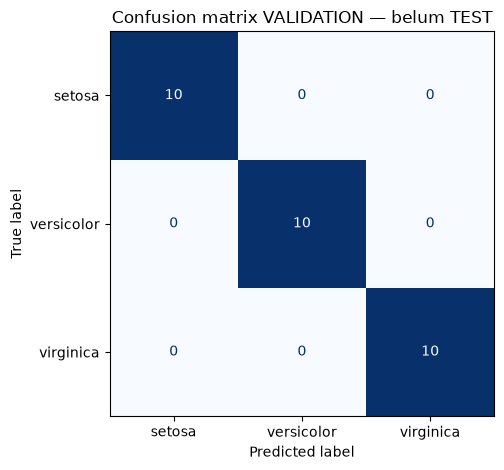

In [19]:
# Kunci konfigurasi final: titik masuk akal yang berorientasi sederhana dan stabil.
# Dapat diganti mahasiswa jika memberikan alasan dari validation dan trade-off.
CLS_FINAL_NAME='all4 | standard | k=5'
assert CLS_FINAL_NAME in cls_fitted
cls_model,cls_features=cls_fitted[CLS_FINAL_NAME]
val_pred=cls_model.predict(Xc_val[cls_features])
print('CLS_FINAL_NAME:',CLS_FINAL_NAME)
print('Validation macro-F1:',round(f1_score(yc_val,val_pred,average='macro'),4))
ConfusionMatrixDisplay.from_predictions(yc_val,val_pred,display_labels=iris.target_names,cmap='Blues',colorbar=False)
plt.title('Confusion matrix VALIDATION — belum TEST');plt.tight_layout();plt.show()

**P7 — Pilihan fitur dan k berdasarkan bukti**

**✍️ JAWABAN:** Bandingkan petal2 vs sepal2, k=1/3/5/9/15, dan scaling. Jelaskan mengapa distribusi kelas dan overlap lebih relevan daripada normalitas. Tuliskan nilai F1, kemungkinan bias–variance, serta alasan konfigurasi final.

**Ringkasan Macro-F1 VALIDATION:**

| Fitur / scaler | k=1 | k=3 | k=5 | k=9 | k=15 |
|---|---|---|---|---|---|
| all4 / none | 1,000 | 1,000 | 1,000 | 1,000 | 1,000 |
| all4 / standard | 0,933 | 1,000 | **1,000** | 1,000 | 0,967 |
| petal2 / none & standard | 1,000 | 0,967 | 0,967 | 0,967 | 0,967 |
| sepal2 / none | 0,576 | 0,798 | 0,766 | 0,731 | 0,693 |
| sepal2 / standard | 0,576 | 0,724 | 0,738 | 0,667 | 0,703 |

- **petal2 vs sepal2:** petal jauh lebih informatif (0,967–1,000 vs 0,576–0,798). Hasil ini cocok dengan EDA: kelas terpisah jelas di petal, sedangkan di sepal versicolor–virginica sangat overlap.
- **Pengaruh k:** k = 1 punya F1 **train** 0,989–1,000 (praktis menghafal) dan di validation paling labil (sepal2 0,576; all4/standard 0,933). Ini tanda **variance tinggi**. k terlalu besar (15) mulai menurun di all4/standard dan sepal2, karena tetangga jauh dari kelas lain ikut voting (**bias** naik). k = 3–9 adalah daerah aman.
- **Scaling:** di Iris efeknya kecil dan tidak konsisten (all4 k=1: none 1,000 vs standard 0,933; sepal2 none sedikit lebih baik). Semua fitur sudah dalam cm dengan rentang mirip, jadi beda tipis ini cuma efek 1–2 bunga di daerah overlap.
- **Distribusi kelas & overlap > normalitas:** yang menentukan error KNN adalah apakah tetangga di sekitar titik berasal dari kelas yang sama. Jadi yang penting adalah **seberapa besar daerah overlap** dan **seimbang tidaknya kelas** (di sini seimbang 30/30/30, jadi voting tidak bias ke kelas mayoritas). Bentuk distribusi tiap fitur tidak berpengaruh langsung.
- **Konfigurasi final: all4 | standard | k = 5**, Macro-F1 val **1,000**, F1 train 0,978 (tidak menghafal seperti k = 1). Banyak run seri di 1,000, jadi aku pakai pertimbangan tambahan: k = 5 berada di tengah daerah stabil (k = 3–9 sama-sama 1,000), dan StandardScaler dipertahankan supaya pipeline tetap aman kalau fitur nanti beda skala. Konsistensinya dengan LogReg (sama-sama all4 + standard) juga membuat perbandingannya adil. Satu bunga di validation = 0,033 poin, jadi seri-seri ini tidak bisa dibedakan lebih jauh dengan 30 data.


**✍️ JAWABAN P7B:** Jelaskan apakah PCA(2) menyimpan variasi yang cukup dan apa dampaknya pada Macro-F1 dibandingkan fitur asli. Apakah komponen PCA mudah diinterpretasi sebagai satu ukuran bunga?

PCA(2) menyimpan **95,83%** variansi (PC1 73,08% + PC2 22,76%) dari 4 fitur yang distandardisasi, jadi informasinya sebagian besar masih ada. Tapi Macro-F1 KNN k=5 turun dari **1,000** (all4 STD) ke **0,9327** (±2 bunga salah dari 30). Sekitar 4% variansi yang dibuang ternyata masih membantu memisahkan versicolor–virginica di daerah overlap. PCA memilih arah dengan **variansi terbesar**, bukan arah yang **paling memisahkan kelas** (PCA tidak melihat label), jadi reduksi dimensi tidak otomatis bikin skor naik.

**Interpretasi:** komponen PCA **tidak** bisa dibaca sebagai satu ukuran bunga. Setiap PC adalah kombinasi linear dari keempat fitur (dalam satuan z-score), jadi PC1 kira-kira "ukuran bunga secara umum" dengan bobot campuran petal dan sepal. Untuk 4 fitur yang sudah mudah ditafsirkan, PCA di sini justru menurunkan interpretabilitas dan skor.


## P8 — Menyimpulkan kelayakan model dari EDA (P1–P7)
**Gunakan bukti yang berasal dari TRAIN/VALIDATION, bukan bentuk histogram saja.**

- **Linear Regression** untuk target numerik Diabetes: hubungan prediksi yang cukup linear, residual tidak memperlihatkan pola sistematis dominan, dan generalisasi diperiksa; normalitas fitur X bukan syarat utama.
- **Logistic Regression** untuk klasifikasi Iris: skor linear diubah menjadi probabilitas (softmax untuk 3 kelas); periksa pemisahan antar kelas, overlap, regularisasi, dan confusion matrix. Distribusi normal fitur tidak wajib.
- **KNNClassifier** untuk Iris: ukuran kedekatan lokal bermakna, skala fitur sesuai, dimensi terkelola, dan pemilihan k diuji pada validation; tidak mengasumsikan normalitas.

Pilih model klasifikasi akhir dari kandidat KNN **atau** Logistic berdasarkan validation dan tujuan, catat trade-off. Jangan membandingkan RMSE Diabetes dengan Macro-F1 Iris. Jawab minimal 5 kalimat dengan angka sebelum membuka TEST.

**✍️ JAWABAN P8:** Bedakan tiga model (Linear Regression, KNN, Logistic Regression) menurut tujuan, bentuk hasil, mekanisme prediksi, metrik dan kondisi data. Jelaskan mengapa KNN dan Logistic bisa dibandingkan pada Iris dengan split sama, sedangkan LR Diabetes berbeda tugas. Sebutkan dua bukti EDA dan dua keterbatasan inferensi.

| Aspek | Linear Regression (Diabetes) | KNNClassifier (Iris) | Logistic Regression (Iris) |
|---|---|---|---|
| Tujuan | Prediksi angka kontinu | Prediksi kelas | Prediksi kelas + peluang |
| Bentuk hasil | Angka (bisa berapa saja) | Label hasil voting | Probabilitas softmax (jumlah 1) → argmax |
| Mekanisme | Kombinasi linear w·x + b (least-squares) | Jarak ke k tetangga, voting mayoritas | Skor linear → softmax, dilatih dengan Log Loss |
| Metrik | MAE, RMSE, R² | Macro-F1, balanced accuracy | Macro-F1, Log Loss |
| Kondisi data | Hubungan ±linear, residual tanpa pola kuat | Jarak bermakna, fitur diskalakan, dimensi rendah | Kelas ±terpisah linear, regularisasi C |

Untuk Diabetes, LR 10 fitur memberi RMSE validation 56,20 dan R² 0,519, jauh di atas baseline median (R² −0,054). Residual train cukup simetris (skew 0,21) dan R² train 0,496 ≈ val 0,519, jadi modelnya layak tapi jelas *underfit*. **KNN dan LogReg bisa dibandingkan langsung** karena tugasnya sama (3 kelas Iris), split-nya sama (90/30/30, seed 2026), fiturnya sama (all4 + StandardScaler), dan metriknya sama (Macro-F1 val 1,000 vs 0,9666). **LR Diabetes tidak bisa dibandingkan** dengan keduanya: targetnya angka, datanya beda, dan RMSE tidak punya padanan dengan Macro-F1. Normalitas fitur tidak jadi syarat untuk ketiganya.

**Dua bukti EDA:** (1) korelasi BMI–target 0,56 dan `s5` 0,525 menunjukkan ada sinyal linear di Diabetes, jadi LR masuk akal dicoba; (2) di Iris, kelas terpisah jelas di fitur petal (setosa ≤ 1,9 cm), dan overlap cuma di versicolor–virginica, jadi model berbasis jarak/batas linear sederhana pun sudah cukup.

**Dua keterbatasan inferensi:** (1) validation Iris cuma 30 baris, jadi 1 bunga = 3,3 poin dan selisih KNN–LogReg tidak signifikan; (2) Diabetes cuma 442 pasien dengan multikolinearitas tinggi (VIF `s1` ±74), jadi koefisien LR tidak boleh dibaca sebagai efek sebab-akibat, apalagi dipakai untuk keputusan klinis.


## P9 — Evaluasi FINAL pada test, satu kali setelah konfigurasi terkunci
Jalankan hanya setelah **REG_FINAL_NAME** dan **CLS_FINAL_NAME** sudah diputuskan berdasarkan validation. Untuk laporan, sertakan angka final dan jelaskan bahwa test tidak dipakai mengubah keputusan.

REG_FINAL_NAME: LinearRegression 10 fitur TEST: {'MAE_test': 41.523, 'RMSE_test': np.float64(52.336), 'R2_test': 0.539}
CLS_FINAL_NAME: all4 | standard | k=5 TEST: {'accuracy_test': 0.933, 'macro_F1_test': 0.933, 'balanced_accuracy_test': 0.933}


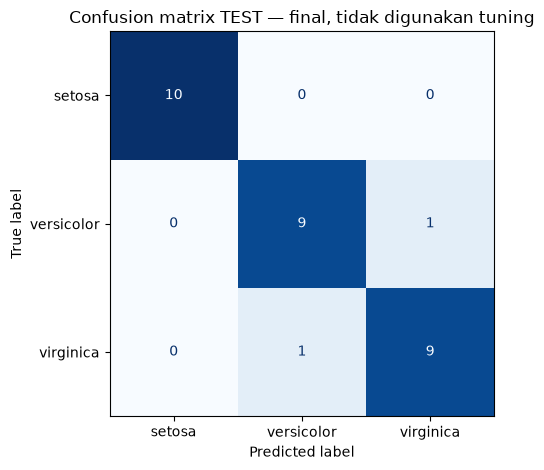

In [20]:
# Refitting pada TRAIN+VALIDATION (pilihan dan parameter sudah dikunci), lalu TEST satu kali.
reg_final_template,reg_features=reg_fitted[REG_FINAL_NAME]
from sklearn.base import clone
reg_final=clone(reg_final_template)
reg_final.fit(Xr_trainval[reg_features],yr_trainval)
reg_test_pred=reg_final.predict(Xr_test[reg_features])
reg_test_metrics={'MAE_test':mean_absolute_error(yr_test,reg_test_pred),
                  'RMSE_test':np.sqrt(mean_squared_error(yr_test,reg_test_pred)),
                  'R2_test':r2_score(yr_test,reg_test_pred)}
cls_final_template,cls_features=cls_fitted[CLS_FINAL_NAME]
cls_final=clone(cls_final_template)
cls_final.fit(Xc_trainval[cls_features],yc_trainval)
cls_test_pred=cls_final.predict(Xc_test[cls_features])
cls_test_metrics={'accuracy_test':accuracy_score(yc_test,cls_test_pred),
                 'macro_F1_test':f1_score(yc_test,cls_test_pred,average='macro'),
                 'balanced_accuracy_test':balanced_accuracy_score(yc_test,cls_test_pred)}
print('REG_FINAL_NAME:',REG_FINAL_NAME,'TEST:',{k:round(v,3) for k,v in reg_test_metrics.items()})
print('CLS_FINAL_NAME:',CLS_FINAL_NAME,'TEST:',{k:round(v,3) for k,v in cls_test_metrics.items()})
ConfusionMatrixDisplay.from_predictions(yc_test,cls_test_pred,display_labels=iris.target_names,cmap='Blues',colorbar=False)
plt.title('Confusion matrix TEST — final, tidak digunakan tuning');plt.tight_layout();plt.show()

**P9 — Analisis generalisasi final**

**✍️ JAWABAN:** Tuliskan hasil test, bandingkan dengan validation, analisis risiko overfitting dan kemungkinan error per kelas. Jangan melakukan penyesuaian berdasarkan skor test.

**Regresi: LinearRegression 10 fitur** (refit di train + val = 353 pasien, test 89):

| | MAE | RMSE | R² |
|---|---|---|---|
| Validation | 46,63 | 56,20 | 0,519 |
| **Test** | **41,52** | **52,34** | **0,539** |

Skor test malah sedikit lebih baik dari validation. Kemungkinan karena model di-refit dengan data lebih banyak dan test set kebetulan sedikit lebih "mudah". Tidak ada tanda overfitting (train 0,496 / val 0,519 / test 0,539 konsisten). Tapi R² ±0,54 artinya hampir setengah variasi target masih tidak terjelaskan, dan RMSE ±52 poin masih besar dibanding rentang target 31–346.

**Klasifikasi: KNN all4 + standard + k=5** (refit di train + val = 120 bunga, test 30):
- Accuracy = Macro-F1 = balanced accuracy = **0,933** (28/30), turun dari 1,000 di validation.
- Confusion matrix test (baris aktual S/V/G): [[10, 0, 0], [0, 9, **1**], [0, **1**, 9]]; recall per kelas 1,0 / 0,9 / 0,9.
- **Error per kelas:** setosa 100% benar. Kedua kesalahan ada di **versicolor ↔ virginica**: ID 72 (6,3; 2,5; 4,9; 1,5), aslinya versicolor, diprediksi virginica, dan ID 133 (6,3; 2,8; 5,1; 1,5), aslinya virginica, diprediksi versicolor. Keduanya persis di daerah overlap petal yang sudah terlihat di EDA.

**Analisis:** turun dari 1,000 ke 0,933 = **2 bunga**. Ini bukan overfitting parah (F1 train 0,978 juga ±sama). Ini menunjukkan validation 1,000 terlalu optimis, karena 30 baris validation kebetulan tidak memuat banyak titik di daerah overlap, dan banyak konfigurasi seri di sana. Angka test 0,933 lebih jujur sebagai perkiraan performa di data baru. **Parameter tidak diubah** setelah melihat hasil test, jadi konfigurasinya tetap seperti yang dikunci di P4 dan P7.


## P10 — Laporan terintegrasi dan artefak portofolio
Isi jawaban pada cell Markdown, kemudian **Kernel → Restart & Run All → Save**.

**Kriteria keluaran:** (1) EDA dengan angka dan grafik, (2) tabel model pembanding Diabetes, KNN–Logistic pada Iris, (3) dua perhitungan manual LR, dua contoh voting KNN, serta hitung sigmoid/Log Loss, (4) ablation dengan satu faktor terkendali, (5) alasan pemilihan model, (6) evaluasi final, (7) catatan keterbatasan, (8) tautan commit repositori bila dipublikasikan. Gunakan lisensi dan atribusi dataset sebagaimana README. Jangan menyatakan dataset Diabetes cocok untuk penggunaan klinis hanya karena R² positif.

**P10 — Kesimpulan portofolio (180–250 kata)**

**✍️ JAWABAN AKHIR:** Jelaskan LR untuk angka Diabetes serta KNN dan Logistic Regression untuk kelas Iris. Jelaskan pertanyaan, metode, temuan numerik, pengaruh preprocessing, apa yang tidak bekerja, batas interpretasi, dan langkah perbaikan berikutnya. Tambahkan tautan GitHub/Hugging Face bila digunakan.

Praktikum ini menjawab dua pertanyaan: seberapa baik target numerik Diabetes bisa diprediksi, dan model mana yang paling tepat untuk mengklasifikasi spesies Iris. Untuk Diabetes, Linear Regression 10 fitur menjadi pilihan final. RMSE validation-nya 56,20 dan R² 0,519, sedangkan di test RMSE 52,34 dan R² 0,539. Hasil ini jauh di atas baseline median (R² −0,054), mengalahkan BMI saja (R² 0,362), dan lebih baik dari KNNRegressor terbaik (k = 15 + scaling, RMSE 60,05). Scaling sangat penting untuk KNN (RMSE 73,1 → 65,1) tetapi tidak mengubah prediksi OLS. Model bmi + s5 hampir menyamai 10 fitur, sehingga bisa jadi alternatif yang lebih mudah dijelaskan. Untuk Iris, KNN all4 + StandardScaler + k = 5 mendapat Macro-F1 validation 1,000 dan Logistic Regression 0,9666. Fitur petal jauh lebih informatif daripada sepal, sedangkan PCA(2) malah menurunkan F1 ke 0,933. Di test, KNN mendapat 0,933, dan kedua salahnya ada di overlap versicolor–virginica. Bagian yang tidak bekerja: k = 1 dan sepal saja (F1 0,576), PCA(2), serta LR yang cenderung *underestimate* target tinggi. Batas interpretasinya: validation dan test kecil (1 bunga = 3,3 poin), multikolinearitas s1–s2 membuat koefisien tidak bisa dibaca kausal, dan model Diabetes **bukan** alat keputusan klinis. Langkah berikutnya: memakai cross-validation berulang, mencoba Ridge/Lasso untuk mengatasi multikolinearitas, dan menambahkan fitur nonlinear.

Repositori: https://github.com/usd-ml-2026/255314091_ml_usd/tree/main/P10


## P11 — Ekspor hasil untuk portofolio / LMS
Jalankan setelah semua eksperimen selesai. Berkas `P10_Hasil_Validasi.csv` menyimpan tabel eksperimen validasi, dan `P10_Final_Config.json` merekam konfigurasi yang dipilih. **Jangan mengunggah data pasien yang mengidentifikasi individu**; dataset praktikum ini tidak mengandung identitas personal. Untuk pembelajaran, cukup unggah kode, sumber, statistik agregat, dan grafik.

Ekspor `cls_table` setelah P7D kini memuat kandidat KNN dan Logistic; nilai `k` untuk Logistic kosong karena bukan parameter model tersebut.

In [21]:
from pathlib import Path
import json
work=Path.cwd()
reg_export=reg_table.copy();reg_export.insert(0,'tugas','regresi_diabetes')
cls_export=cls_table.copy();cls_export.insert(0,'tugas','klasifikasi_iris')
pd.concat([reg_export,cls_export],ignore_index=True).to_csv(work/'P10_Hasil_Validasi.csv',index=False)
configuration={'REG_FINAL_NAME':str(REG_FINAL_NAME),'CLS_FINAL_NAME':str(CLS_FINAL_NAME),
 'seed':SEED,'reg_test_metrics':{k:float(v) for k,v in reg_test_metrics.items()},
 'cls_test_metrics':{k:float(v) for k,v in cls_test_metrics.items()},
 'data_sources':['scikit-learn load_diabetes(scaled=False)','scikit-learn load_iris()']}
(work/'P10_Final_Config.json').write_text(json.dumps(configuration,ensure_ascii=False,indent=2),encoding='utf-8')
print('CSV dan JSON tersimpan di:',work)

CSV dan JSON tersimpan di: D:\MLGITHUB\P10


## Daftar referensi dan keterlacakan
- scikit-learn, `load_diabetes`, `scaled=False`: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html
- scikit-learn, `load_iris`: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html
- scikit-learn, [Linear Models](https://scikit-learn.org/stable/modules/linear_model.html) dan [Nearest Neighbors](https://scikit-learn.org/stable/modules/neighbors.html).
- Iris asli: R. A. Fisher (1936), UCI Machine Learning Repository https://doi.org/10.24432/C56C76.

**Reproducibility:** split seed 2026; StandardScaler hanya `fit()` pada TRAIN melalui Pipeline; validasi tidak digunakan untuk fit transform; test tidak digunakan untuk tuning.
- scikit-learn, Logistic Regression: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
